In [189]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [190]:
# 1. Leer los archivos. Son antiguos y están en latin-1, no en utf-8.
#    dtype=str para que no se pierdan los ceros de los códigos ("001", "029").
pasajeros = pd.read_csv("datos/CIR0603.ITL.Y5500.csv", dtype=str, encoding="latin-1")
cabeceras = pd.read_csv("datos/CIR0603.HDRSDAT.csv", dtype=str, encoding="latin-1")
oficios = pd.read_csv("datos/CIR0603.OCCCOD.csv", dtype=str, encoding="latin-1")
puertos = pd.read_csv("datos/CIR0603.PTOCOD.csv", dtype=str, encoding="latin-1")
paises = pd.read_csv("datos/CIR0603.CTYCOD.csv", dtype=str, encoding="latin-1")

# 2. Unir cada pasajero con su lista: barco, puerto de salida y fecha.
datos = pasajeros.merge(cabeceras, on="MID")

# 3. Traducir los códigos con las tablas.
datos["oficio"] = datos["OCC"].map(dict(zip(oficios["CODE"], oficios["OCC"])))
datos["puerto_salida"] = datos["PORT"].map(dict(zip(puertos["CODE"], puertos["PORT"])))
datos["pais"] = datos["COUNTRY"].map(dict(zip(paises["CODE"], paises["COUNTRY"])))

# 4. La fecha viene como texto ("4/4/1894 0:00:00"). La pasamos a fecha y sacamos el año.
datos["fecha"] = pd.to_datetime(datos["ARR_DATE"], format="%m/%d/%Y %H:%M:%S")
datos["anio"] = datos["fecha"].dt.year

# Este codigo me sirve para ver que codigos me fallaron.

datos.loc[datos["puerto_salida"].isna(), "PORT"].value_counts()
datos.loc[datos["oficio"].isna(), "OCC"].value_counts()

# Los imprimo para ver cuales son. 
print(datos.loc[datos["puerto_salida"].isna(), "PORT"].value_counts())
print(datos.loc[datos["oficio"].isna(), "OCC"].value_counts())

# Rellenar los valores nulos que quedaron sin match en el mapeo.

datos["puerto_salida"] = datos["puerto_salida"].fillna("DESCONOCIDO")
datos["oficio"] = datos["oficio"].fillna("DESCONOCIDO")


# 5. Nombres en español y solo las columnas que vamos a usar.
datos = datos.rename(columns={
    "LN": "apellido",
    "FN": "nombre",
    "AGE": "edad",
    "SEX": "sexo",
    "LITR": "sabe_leer",
    "LRES": "ultima_residencia",
    "DEST": "destino",
    "PASG": "tipo_pasaje",
    "SHIP": "barco",
    "MID": "lista",
})
datos = datos[["lista", "apellido", "nombre", "edad", "sexo", "oficio", "sabe_leer", "pais",
               "ultima_residencia", "destino", "tipo_pasaje", "barco", "puerto_salida", "fecha", "anio"]]

# 6. Guardar en un solo CSV para el EDA.
datos.to_csv("datos/pasajeros_italianos.csv", index=False)
print(datos.shape)
datos.head() 


PORT
O89    1081
Name: count, dtype: int64
OCC
AGRC       747
SVYR        10
HRDSR        5
PPTR         2
SHMKR        2
INFU         2
AY-OFF       2
CV           1
POST         1
HBRDSR       1
TRDSM        1
 NN          1
CRTM         1
MASN         1
LASBR        1
SMHK         1
LAbr         1
labr         1
FMRT         1
CVER         1
BT-SHMK      1
SHW          1
SLTR         1
T            1
Name: count, dtype: int64
(845368, 15)


,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,anio
0,00083279,NaN,NaN,029,M,MERCHANT,U,ITALY,U,NEW YORK,S13,KAISER WILHELM II,GENOA,1895-03-27,1895
1,00079013,NaN,ANGELA,015,F,HOUSEWIFE,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
2,00079013,NaN,ANGELA M.,008,F,LABORER,U,ITALY,U,BUFFALO,S13,CALIFORNIA,NAPLES,1895-12-03,1895
3,00079013,NaN,ANGELO,024,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
4,00079013,NaN,ANTONIA,035,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895


In [191]:
# Buscamos cuántas celdas tienen exactamente la letra 'O' seguida de '89'
filas_con_letra = cabeceras[cabeceras["PORT"] == "O89"]

print("Cantidad de filas afectadas:", len(filas_con_letra))

Cantidad de filas afectadas: 1


In [192]:
# Corregir el error tipográfico donde la 'O' reemplazaba al '0' en PORT
cabeceras["PORT"] = cabeceras["PORT"].str.replace("O", "0", regex=False)
print("hecho")

hecho


In [193]:
# Investigo alguno de los oficios raros, por ejemplo "AGRC" o las diferencias de mayúsculas
print(oficios[oficios["CODE"] == "AGRC"]) 

Empty DataFrame
Columns: [CODE, OCC]
Index: []


En el .csv de cabeceras del df , tenia un error tipografico donde un puerto en vez de  llamarse "089" se llamaba "O89" esto genero que pandas buscara "O89",no encontrara nada y devolviera valores nulos. Por esa razon 1081 personas se quedaron sin puerto.
En la tabla oficios, esos codigos que salieron en mayusculas y minusculas son codigos que no existen en la tabla oficios. Significa que son codigos huerfanos.

## 1. ¿Que tengo?

In [194]:
datos.shape # Aca vemos la cantidad de filas y columnas que tiene el df.

(845368, 15)

In [195]:
datos.info() # Aca podemos ver que datos estan completos solo lista, edad, pais, barco, fecha y año.


<class 'pandas.DataFrame'>
RangeIndex: 845368 entries, 0 to 845367
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   lista              845368 non-null  str           
 1   apellido           845344 non-null  str           
 2   nombre             845288 non-null  str           
 3   edad               845368 non-null  str           
 4   sexo               845365 non-null  str           
 5   oficio             845368 non-null  str           
 6   sabe_leer          845139 non-null  str           
 7   pais               845368 non-null  str           
 8   ultima_residencia  844518 non-null  str           
 9   destino            845365 non-null  str           
 10  tipo_pasaje        845105 non-null  str           
 11  barco              845368 non-null  str           
 12  puerto_salida      845368 non-null  str           
 13  fecha              845368 non-null  datetime64[us]
 14 

In [196]:
datos.columns 

Index(['lista', 'apellido', 'nombre', 'edad', 'sexo', 'oficio', 'sabe_leer',
       'pais', 'ultima_residencia', 'destino', 'tipo_pasaje', 'barco',
       'puerto_salida', 'fecha', 'anio'],
      dtype='str')

In [197]:
datos = datos.rename(columns={"anio": "año"})  # Acomodamos lo errores de escritura..
datos.head()

,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,año
0,00083279,NaN,NaN,029,M,MERCHANT,U,ITALY,U,NEW YORK,S13,KAISER WILHELM II,GENOA,1895-03-27,1895
1,00079013,NaN,ANGELA,015,F,HOUSEWIFE,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
2,00079013,NaN,ANGELA M.,008,F,LABORER,U,ITALY,U,BUFFALO,S13,CALIFORNIA,NAPLES,1895-12-03,1895
3,00079013,NaN,ANGELO,024,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
4,00079013,NaN,ANTONIA,035,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895


In [198]:
datos.describe().round(2) # Aca podemos ver un resumen estadistico de los datos numericos.

,fecha,año
count,845368,845368.00
mean,1893-07-15 12:55:09.979086,1893.06
min,1855-01-11 00:00:00,1855.00
25%,1890-04-09 00:00:00,1890.00
50%,1893-12-21 00:00:00,1893.00
75%,1898-05-05 00:00:00,1898.00
max,1900-12-31 00:00:00,1900.00
std,NaN,5.66


In [199]:
datos.describe() # Aca se puede ver que encontramos valores nulos disfrazados de "-" y que la edad minima es -1, lo cual es imposible. Por lo tanto, vamos a limpiar los datos.
datos

,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,año
0,00083279,NaN,NaN,029,M,MERCHANT,U,ITALY,U,NEW YORK,S13,KAISER WILHELM II,GENOA,1895-03-27,1895
1,00079013,NaN,ANGELA,015,F,HOUSEWIFE,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
2,00079013,NaN,ANGELA M.,008,F,LABORER,U,ITALY,U,BUFFALO,S13,CALIFORNIA,NAPLES,1895-12-03,1895
3,00079013,NaN,ANGELO,024,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
4,00079013,NaN,ANTONIA,035,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845363,00081012,ZWEIFEL,JOSUA,023,M,MASON,U,ITALY,U,USA,S13,LA GASCOGNE,HAVRE,1887-05-02,1887
845364,00000729,ZYZO,FRANCESCANTONIO,025,M,FARMER,U,ITALY,OLIVETO,NEW YORK,S13,HINDOUSTAN,NAPLES,1894-05-15,1894
845365,00083080,----ZZA,ALFONSO,022,M,LABORER,N,ITALY,ALESSANDRIA,PORT TAMPA FL,S13,BURGUNDIA,NAPLES,1898-06-13,1898
845366,00081738,----ZZATI,CARMELA,008,F,"CHILD, YOUNGSTER",U,ITALY,SCIACCA,NEW YORK,S13,STURA,NAPLES,1890-12-19,1890


## 2. ¿Que me falta?

In [200]:
datos.isna().sum() #Aca queria ver que columnas tienen esos valores nulos. Son todas aquella que no llevan 0.

lista                  0
apellido              24
nombre                80
edad                   0
sexo                   3
oficio                 0
sabe_leer            229
pais                   0
ultima_residencia    850
destino                3
tipo_pasaje          263
barco                  0
puerto_salida          0
fecha                  0
año                    0
dtype: int64

In [201]:
porcentaje = datos.isna().sum() / len(datos) * 100  # Ahora lo voy a hacer porcentual asi veo si es significativo para el df o no.
porcentaje.round(3)                                 # No son para nada significativos, por ende vamos a proceder a reemplazarlos / eliminarlos.

lista                0.000
apellido             0.003
nombre               0.009
edad                 0.000
sexo                 0.000
oficio               0.000
sabe_leer            0.027
pais                 0.000
ultima_residencia    0.101
destino              0.000
tipo_pasaje          0.031
barco                0.000
puerto_salida        0.000
fecha                0.000
año                  0.000
dtype: float64

In [202]:
datos = datos.dropna(subset = ["destino", "apellido","sexo"]) #Aca vamos a eliminar las filas que tienen nulos en las columnas (destino, apellido y sexo), ya que no afectan al resto de los datos.
datos.shape

(845338, 15)

In [203]:
datos["puerto_salida"].value_counts().head(20) # Aca vemos los 20 puertos de salida mas frecuentes, y vemos que un puerto es "DESCONOCIDO".

puerto_salida
NAPLES                         336050
HAVRE                          127806
GENOA                          103530
MARSEILLES & NAPLES             48147
GENOA, GIBRALTAR & NAPLES       20772
GENOA & GIBRALTAR               20658
PALERMO                         20398
NAPLES & PALERMO                17191
GIBRALTAR & NAPLES              15662
GENOA & NAPLES                  15570
UNKNOWN                         10503
ANTWERP                         10166
MARSEILLES                       9501
BORDEAUX                         7357
MEDITERRANEAN PORTS              5962
NAPLES & TRIESTE                 5936
HAMBURG & HAVRE                  5627
GIBRALTAR, NAPLES & PALERMO      5278
LIVERPOOL & QUEENSTOWN           4308
BOULOGNE & ROTTERDAM             4136
Name: count, dtype: int64

In [204]:

datos["oficio"].value_counts().head(20)

oficio
LABORER                         283769
FARMER                          145077
PEASANT                          58284
COUNTRY MAN                      44827
CHILD, YOUNGSTER                 42144
NIECE, NEPHEW                    24887
HOUSEWIFE                        19814
WIFE                             16340
SHOEMAKER                        15426
SON                              12695
TAILOR                           11492
MINER                            10794
DAUGHTER                         10105
MASON                             9432
COUNTRY WOMAN                     7856
SAILOR                            7605
UNKNOWN                           7570
BARBER                            7126
INFANT                            7116
SERVANT, GENTLEMAN'S SERVANT      7054
Name: count, dtype: int64

In [205]:
datos["ultima_residencia"].value_counts().head(20)

ultima_residencia
U               423520
NAPOLI           12248
PALERMO           7300
NEW YORK          6920
TERMINI           4823
UNKNOWN           4613
SCIACCA           3878
MESSINA           3325
PHILADELPHIA      2638
AVELLINO          2612
CAMPOBASSO        2254
POTENZA           2075
SALERNO           1848
ITALY             1677
COSENZA           1544
NICASTRO          1502
BROOKLYN          1498
CORLEONE          1461
CEFALU            1407
ISERNIA           1396
Name: count, dtype: int64

In [206]:
datos["sabe_leer"].value_counts().head(20)

sabe_leer
U    503759
N    210562
Y    130786
n         1
y         1
Name: count, dtype: int64

In [207]:
datos["sabe_leer"] = datos["sabe_leer"].replace("n", "N") # Aca arreglo el problable error de mayusculas y minusculas, que pudieron tener en la colmuna de "sabe_leer".
datos["sabe_leer"] = datos["sabe_leer"].replace("y", "Y")
datos["sabe_leer"].value_counts().head(20)    # Procedemos a ver si se reemplazo.

sabe_leer
U    503759
N    210563
Y    130787
Name: count, dtype: int64

In [208]:
datos["tipo_pasaje"].value_counts().head(20)

tipo_pasaje
S13    813512
S09     14454
I13      3769
T13      3069
T09      2770
C13      2022
U13      1194
C09       867
S0        779
L27       489
I09       421
S9        368
S15       171
913       163
FE.       143
S1        120
U09       106
F29        87
MLA        74
S 9        58
Name: count, dtype: int64

In [209]:
datos = datos.replace("UNKNOWN", "DESCONOCIDO")  # Dado a la cantidad de "UNKNOWN" que hay en el df, voy a rellenarlos con "Desconocido". Ya que queda mejor para categorizarlos.

In [210]:
datos["oficio"].value_counts().head(20) # Comprobamos si se relleno.

oficio
LABORER                         283769
FARMER                          145077
PEASANT                          58284
COUNTRY MAN                      44827
CHILD, YOUNGSTER                 42144
NIECE, NEPHEW                    24887
HOUSEWIFE                        19814
WIFE                             16340
SHOEMAKER                        15426
SON                              12695
TAILOR                           11492
MINER                            10794
DAUGHTER                         10105
MASON                             9432
DESCONOCIDO                       8387
COUNTRY WOMAN                     7856
SAILOR                            7605
BARBER                            7126
INFANT                            7116
SERVANT, GENTLEMAN'S SERVANT      7054
Name: count, dtype: int64

In [211]:
datos= datos.replace("-", "DESCONOCIDO") # Aca vemos que se reemplazo correctamente los valores nulos disfrazados de "-".
datos                                    #Comprobamos si se reemplazo correctamente.

,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,año
24,00079013,DESCONOCIDO,DESCONOCIDO,002,F,HOUSEWIFE,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
25,00079006,DESCONOCIDO,DESCONOCIDO,005,M,SON,U,ITALY,U,USA,S13,WERRA,GENOA & NAPLES,1895-11-14,1895
26,00079017,DESCONOCIDO,DESCONOCIDO,006,F,"CHILD, YOUNGSTER",U,ITALY,U,NEW YORK,S13,BOLIVIA,ELEUTHERA & NASSAU,1895-12-10,1895
27,00079013,DESCONOCIDO,DESCONOCIDO,007,F,LABORER,U,ITALY,U,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
28,00083301,DESCONOCIDO,DESCONOCIDO,011,M,LABORER,U,ITALY,U,NEW YORK,S13,BOHEMIA,HAMBURG & HAVRE,1895-05-25,1895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845363,00081012,ZWEIFEL,JOSUA,023,M,MASON,U,ITALY,U,USA,S13,LA GASCOGNE,HAVRE,1887-05-02,1887
845364,00000729,ZYZO,FRANCESCANTONIO,025,M,FARMER,U,ITALY,OLIVETO,NEW YORK,S13,HINDOUSTAN,NAPLES,1894-05-15,1894
845365,00083080,----ZZA,ALFONSO,022,M,LABORER,N,ITALY,ALESSANDRIA,PORT TAMPA FL,S13,BURGUNDIA,NAPLES,1898-06-13,1898
845366,00081738,----ZZATI,CARMELA,008,F,"CHILD, YOUNGSTER",U,ITALY,SCIACCA,NEW YORK,S13,STURA,NAPLES,1890-12-19,1890


In [212]:
datos.isna().sum() # Reviso nuevamente los nulos, para ver si se van eliminando.

lista                  0
apellido               0
nombre                79
edad                   0
sexo                   0
oficio                 0
sabe_leer            229
pais                   0
ultima_residencia    849
destino                0
tipo_pasaje          263
barco                  0
puerto_salida          0
fecha                  0
año                    0
dtype: int64

In [213]:
datos[datos['nombre'].isna()] # Aca quiera ver cual eran los valores NaN.

,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,año
39680,00081020,BALDOCCHI,NaN,016,M,LABORER,U,ITALY,U,NEW YORK,S13,LA NORMANDIE,HAVRE,1887-05-09,1887
52384,00079006,BATTAGLIA,NaN,054,F,WIFE,U,ITALY,U,NEW YORK,S13,WERRA,GENOA & NAPLES,1895-11-14,1895
58233,00079005,BENA,NaN,049,M,HARDWARE MERCHANT,U,ITALY,U,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895
63877,00079005,BERTENETTE,NaN,036,F,OPERA MANAGER,U,ITALY,U,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895
64112,00079005,BERTINETTO,NaN,042,M,HARDWARE MERCHANT,U,ITALY,U,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
777176,00080498,TAMOLINA,NaN,003,F,FARMER,U,ITALY,U,MOUNT-CARMEL,S13,WESTERNLAND,ANTWERP,1884-04-30,1884
782999,00083362,TERESA DI MARIA,NaN,001,F,"NIECE, NEPHEW",N,ITALY,ALTAVILLA,PITTSBURGH,S13,EMS,GENOA,1899-11-23,1899
787132,00079005,TIVOLA,NaN,040,M,HARDWARE MERCHANT,U,ITALY,U,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895
839109,00079005,ZANGHERE,NaN,038,M,HARDWARE MERCHANT,U,ITALY,U,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895


In [214]:
datos= datos.replace("U","DESCONOCIDO")
datos

,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,año
24,00079013,DESCONOCIDO,DESCONOCIDO,002,F,HOUSEWIFE,DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
25,00079006,DESCONOCIDO,DESCONOCIDO,005,M,SON,DESCONOCIDO,ITALY,DESCONOCIDO,USA,S13,WERRA,GENOA & NAPLES,1895-11-14,1895
26,00079017,DESCONOCIDO,DESCONOCIDO,006,F,"CHILD, YOUNGSTER",DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,BOLIVIA,ELEUTHERA & NASSAU,1895-12-10,1895
27,00079013,DESCONOCIDO,DESCONOCIDO,007,F,LABORER,DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,CALIFORNIA,NAPLES,1895-12-03,1895
28,00083301,DESCONOCIDO,DESCONOCIDO,011,M,LABORER,DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,BOHEMIA,HAMBURG & HAVRE,1895-05-25,1895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845363,00081012,ZWEIFEL,JOSUA,023,M,MASON,DESCONOCIDO,ITALY,DESCONOCIDO,USA,S13,LA GASCOGNE,HAVRE,1887-05-02,1887
845364,00000729,ZYZO,FRANCESCANTONIO,025,M,FARMER,DESCONOCIDO,ITALY,OLIVETO,NEW YORK,S13,HINDOUSTAN,NAPLES,1894-05-15,1894
845365,00083080,----ZZA,ALFONSO,022,M,LABORER,N,ITALY,ALESSANDRIA,PORT TAMPA FL,S13,BURGUNDIA,NAPLES,1898-06-13,1898
845366,00081738,----ZZATI,CARMELA,008,F,"CHILD, YOUNGSTER",DESCONOCIDO,ITALY,SCIACCA,NEW YORK,S13,STURA,NAPLES,1890-12-19,1890


In [215]:
# Relleno los nulos restantes con "DESCONOCIDO", asi dejo todo en 0.
columnas_con_nulos = ["nombre", "sabe_leer", "ultima_residencia", "tipo_pasaje"]

for col in columnas_con_nulos:
    datos[col] = datos[col].fillna("DESCONOCIDO")

In [216]:
datos.isna().sum()

lista                0
apellido             0
nombre               0
edad                 0
sexo                 0
oficio               0
sabe_leer            0
pais                 0
ultima_residencia    0
destino              0
tipo_pasaje          0
barco                0
puerto_salida        0
fecha                0
año                  0
dtype: int64

## 4. ¿Hay filas repetidas?

In [217]:
datos.duplicated().sum() # Aca verifico si hay duplicados  y encuentro solo uno que voy a eliminar.

np.int64(537)

In [218]:
datos[datos.duplicated(keep=False)] # Aca lo busco por curiosidad

,lista,apellido,nombre,edad,sexo,oficio,sabe_leer,pais,ultima_residencia,destino,tipo_pasaje,barco,puerto_salida,fecha,año
98,00083267,DESCONOCIDO,AGOSTINO,029,M,LABORER,DESCONOCIDO,ITALY,DESCONOCIDO,CINé,S13,FURST BISMARCK,DUNKIRK,1895-01-25,1895
99,00083323,DESCONOCIDO,ALBIZIO,011,M,"CHILD, YOUNGSTER",DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,AURANIA,LIVERPOOL & QUEENSTOWN,1895-10-03,1895
100,00083332,DESCONOCIDO,ALFREDO,023,M,FISHERMAN,DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,BELGRAVIA,GIBRALTAR & NAPLES,1895-10-23,1895
101,00083296,DESCONOCIDO,ANDREA,016,M,LABORER,DESCONOCIDO,ITALY,DESCONOCIDO,PHILADELPHIA,S13,BURGUNDIA,JERSEY,1895-05-13,1895
102,00083305,DESCONOCIDO,ANDREA,042,M,SAILOR,DESCONOCIDO,ITALY,DESCONOCIDO,BALTIMORE,S13,KAISER WILHELM II,GENOA & GIBRALTAR,1895-06-01,1895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
843533,00079005,ZOLA,DESCONOCIDO,034,M,OPERA MANAGER,DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895
843555,00079005,ZOLA,DESCONOCIDO,034,M,OPERA MANAGER,DESCONOCIDO,ITALY,DESCONOCIDO,NEW YORK,S13,NEW YORK,SOUTHAMPTON,1895-11-11,1895
844441,00083255,ZUCCHELL,ANGELO,025,M,LABORER,DESCONOCIDO,ITALY,PARIS,SAN FRANCISCO,S13,LA GASCOGNE,HAVRE,1899-09-10,1899
844443,00083255,ZUCCHELL,ANGELO,025,M,LABORER,DESCONOCIDO,ITALY,PARIS,SAN FRANCISCO,S13,LA GASCOGNE,HAVRE,1899-09-10,1899


In [219]:
datos = datos.drop_duplicates() # Aca finalmente la borro y compruebo si funciono.
datos.duplicated().sum()

np.int64(0)

## 4. ¿ Como son los números?

In [220]:
datos.describe().round() # Aca podemos ver un resumen estadistico de los datos numericos.

,fecha,año
count,844801,844801.0
mean,1893-07-14 15:53:18.409567,1893.0
min,1855-01-11 00:00:00,1855.0
25%,1890-04-09 00:00:00,1890.0
50%,1893-12-18 00:00:00,1893.0
75%,1898-05-05 00:00:00,1898.0
max,1900-12-31 00:00:00,1900.0
std,NaN,6.0


In [221]:
datos["edad"].max() # Aca vemos la edad maxima que es 912 años. 

'912'

In [222]:
datos["edad"].min() # Aca vemos que la edad minima es 1 año.

'001'

In [223]:
datos[datos["edad"] == datos["edad"].max()].shape[0] # Tenemos 52 personas con la edad de 912 años por ende se debe tratar de una forma de tratar a los nulos. Vamos a proceder a reemplazarlos por "DESCONOCIDO".

52

In [224]:
datos["edad"] = datos["edad"].replace(800, "DESCONOCIDO") # Aca reemplazo el dato de 800 en mi df, ya que la "edad" 800 en mi df significa que es desconocido.
print("HECHO")

HECHO


In [225]:
valores_desconocidos = datos["edad"][datos["edad"] == 800].head()
valores_desconocidos                                            # verifico si me devuelve estos valores o no.

Series([], Name: edad, dtype: str)

In [226]:
# Convertir a número el campo de edad, ya que estaba en texto, reemplazando los valores no numéricos por "nan".
datos["edad"] = pd.to_numeric(datos["edad"], errors="coerce")

# Reemplazo cualquier valor mayor a 110 por "nan"
datos.loc[datos["edad"] > 110, "edad"] = np.nan

In [227]:
datos["edad"] = datos["edad"].apply(lambda x: (x - 900) / 12.0 if 901 <= x <= 912 else x) 
# Aca llama a una funcion rapida para hacer una operacion matematica para poder filtrar los "9NN" de los datos, en donde encontre que son bebes.
# Si la "edad" se encuetra entre 901 y 912, se le resta 900 y se lo divide por 12 meses. Asi el resultado me da un numero decimal, en años.
# En caso que no sea un numero entre ellos, el else se encarga de mostrarlo tal cual.

In [228]:
datos["edad"].max() # Ahora si vemos la edad maxima es 99 años, lo cual es mas razonable.

np.float64(99.0)

In [229]:
datos.describe().round(2) # Aca podemos ver un resumen estadistico de los datos numericos actualizados.

,edad,fecha,año
count,827821.0,844801,844801.00
mean,27.0,1893-07-14 15:53:18.409567,1893.06
min,1.0,1855-01-11 00:00:00,1855.00
25%,19.0,1890-04-09 00:00:00,1890.00
50%,26.0,1893-12-18 00:00:00,1893.00
75%,35.0,1898-05-05 00:00:00,1898.00
max,99.0,1900-12-31 00:00:00,1900.00
std,13.1,NaN,5.66


In [230]:
mediana=datos["edad"].median().round(2)
print("la mediana de edad es: ", mediana, "años") # Aca vemos que la mediana de edad es 26 años.

media = datos["edad"].mean().round(2)
print("la media de edad es: ", media, "años") # Aca vemos que la media de edad es 27 años.

la mediana de edad es:  26.0 años
la media de edad es:  27.0 años


([<matplotlib.axis.XTick at 0x1c9abb1c690>,
 [Text(0, 0, '0'),
  Text(10, 0, '10'),
  Text(20, 0, '20'),
  Text(30, 0, '30'),
  Text(40, 0, '40'),
  Text(50, 0, '50'),
  Text(60, 0, '60'),
  Text(70, 0, '70'),
  Text(80, 0, '80'),
  Text(90, 0, '90')])

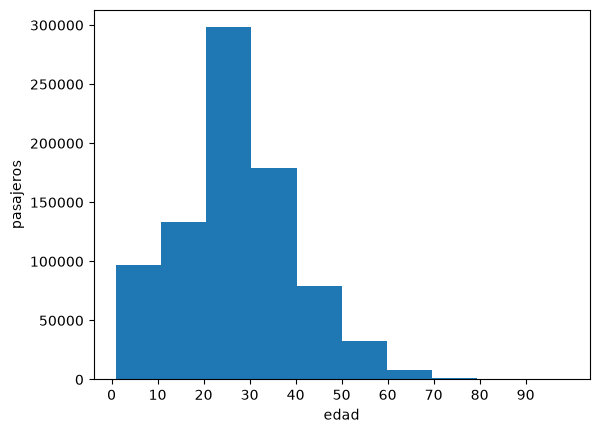

In [231]:
datos["edad"].plot(xlabel="edad", ylabel= "pasajeros", kind= 'hist') # Aca vemos que la mayoria de los pasajeros tienen entre 20 y 30 años.
plt.xticks(range(0, 99, 10))

## 5. ¿Hay algo raro?


In [232]:
adultos_mayores = datos[datos["edad"] >= 99]
print("Cantidad de adultos mayores: ", len(adultos_mayores)) # Habia 51 adultos mayores que tenian 99 años.

Cantidad de adultos mayores:  51


**Aunque biologicamente sea posible que un pasajero haya viajado con la edad de 99 años, en esa epoca se registraban con "99" a aquella personas longevas que desconocian su edad exacta.**

In [233]:
bebes = datos[datos["edad"] <= 1]
print("Cantidad de bebes: ", len(bebes)) # Aca podemos ver que 9148 bebes o infantes, migraron a lo largo de estos años.

Cantidad de bebes:  9143


**En el .csv de cabeceras del df , tenia un error tipografico donde un puerto en vez de  llamarse "089" se llamaba "O89" esto genero que pandas buscara "O89",no encontrara nada y devolviera valores nulos. Por esa razon 1081 personas se quedaron sin puerto. En la tabla oficios, esos codigos que salieron en mayusculas y minusculas son codigos que no existen en la tabla oficios. Significa que son codigos huerfanos, por ende tuve que reemplazarlos por "DESCONOCIDO"**

## 6. ¿Que hay más?

In [234]:
datos["puerto_salida"].value_counts().head(10) # Estos son los 10 puertos de salida mas frecuentes.

puerto_salida
NAPLES                       335893
HAVRE                        127784
GENOA                        103399
MARSEILLES & NAPLES           48137
GENOA, GIBRALTAR & NAPLES     20763
GENOA & GIBRALTAR             20603
PALERMO                       20397
NAPLES & PALERMO              17191
GIBRALTAR & NAPLES            15654
GENOA & NAPLES                15565
Name: count, dtype: int64

In [235]:
datos["oficio"].value_counts().head(10) # Aca podemos ver los 10 oficios mas frecuentes de los inmigrantes italianos.

oficio
LABORER             283558
FARMER              145043
PEASANT              58270
COUNTRY MAN          44795
CHILD, YOUNGSTER     42133
NIECE, NEPHEW        24884
HOUSEWIFE            19806
WIFE                 16326
SHOEMAKER            15418
SON                  12694
Name: count, dtype: int64

In [236]:
(datos["oficio"].value_counts() / len(datos) * 100).round(1).head(10) # El oficio mas popular entre los inmigrantes italianos era todo lo relacionado con la agricultura.

oficio
LABORER             33.6
FARMER              17.2
PEASANT              6.9
COUNTRY MAN          5.3
CHILD, YOUNGSTER     5.0
NIECE, NEPHEW        2.9
HOUSEWIFE            2.3
WIFE                 1.9
SHOEMAKER            1.8
SON                  1.5
Name: count, dtype: float64

In [237]:
datos["ultima_residencia"].value_counts().head(10)

ultima_residencia
DESCONOCIDO     428695
NAPOLI           12246
PALERMO           7298
NEW YORK          6919
TERMINI           4784
SCIACCA           3876
MESSINA           3325
PHILADELPHIA      2638
AVELLINO          2611
CAMPOBASSO        2254
Name: count, dtype: int64

In [238]:
datos["ultima_residencia"] = datos["ultima_residencia"].replace("U", "DESCONOCIDO") # Voy a unificar UNKNOWN ("U") y DESCONOCIDO en la columna de ultima residencia, ya que son lo mismo.

In [239]:
datos["ultima_residencia"].value_counts().head(10) # Cambio aplicado correctamente.

ultima_residencia
DESCONOCIDO     428695
NAPOLI           12246
PALERMO           7298
NEW YORK          6919
TERMINI           4784
SCIACCA           3876
MESSINA           3325
PHILADELPHIA      2638
AVELLINO          2611
CAMPOBASSO        2254
Name: count, dtype: int64

In [240]:
(datos["ultima_residencia"].value_counts() / len(datos) * 100).round(1).head() # Aca podemos apreciar que mas del 50% de los inmigrantes italianos, no tenian una ultima residencia conocida.

ultima_residencia
DESCONOCIDO    50.7
NAPOLI          1.4
PALERMO         0.9
NEW YORK        0.8
TERMINI         0.6
Name: count, dtype: float64

In [241]:
datos["sabe_leer"].value_counts().head() # Aca podemos ver la cantidad de personas que saben leer y las que no.

sabe_leer
DESCONOCIDO    503466
N              210555
Y              130780
Name: count, dtype: int64

In [242]:
datos["sabe_leer"] = datos["sabe_leer"].replace("U", "DESCONOCIDO") # Voy a unificar UNKNOWN ("U") y DESCONOCIDO en la columna de sabe_leer, ya que son lo mismo.

In [243]:
(datos["sabe_leer"].value_counts()/len(datos) * 100).round(1) 

# El cambio se aplico correctamente y podemos ver que el casi el 25% de los inmigrantes italianos no saben leer, solo el 15.5% sabia leer y escribir. Y casi el 60% se desconoce si saben leer o no.

sabe_leer
DESCONOCIDO    59.6
N              24.9
Y              15.5
Name: count, dtype: float64

In [244]:
datos["tipo_pasaje"].value_counts().head(10)

tipo_pasaje
S13    812975
S09     14454
I13      3769
T13      3069
T09      2770
C13      2022
U13      1194
C09       867
S0        779
L27       489
Name: count, dtype: int64

In [245]:
(datos["tipo_pasaje"].value_counts() / len(datos) * 100).round(1).head() 

# Aca podemos ver que el 96.2% de los inmigrantes italianos viajaban en tercera clase, y solo el 3.8% en intermedia y primera clase.

tipo_pasaje
S13    96.2
S09     1.7
I13     0.4
T13     0.4
T09     0.3
Name: count, dtype: float64

In [246]:
((datos["sexo"].value_counts(normalize=True) * 100).round(1)).head() # Aca quiero ver el porcentaje de hombres y mujeres que migraron a lo largo de estos años.

sexo
M              74.3
F              25.6
DESCONOCIDO     0.1
N               0.0
m               0.0
Name: proportion, dtype: float64

In [247]:
datos["sexo"] = datos["sexo"].replace("m", "M") # Vamos a redefinir los datos de sexo, reemplazamos el minúscula 'm' a mayúscula 'M'.
datos["sexo"] = datos["sexo"].replace({"U": "DESCONOCIDO", "N": "DESCONOCIDO"}) #Unificar la 'U' y valores anómalos como 'N' a 'DESCONOCIDO'

print(((datos["sexo"].value_counts(normalize=True) * 100).round(1)).head()) 

# Ahora podemos decir que la mayoria de los inmigrantes italianos eran hombres, con un 74.3% y solo el 25.6% eran mujeres. Y un 0.1% se desconoce su sexo.

sexo
M              74.3
F              25.6
DESCONOCIDO     0.1
Name: proportion, dtype: float64


## 7. ¿Cambia algo de un grupo al otro?

In [248]:
edad_por_sexo = datos.groupby("sexo")["edad"].mean().round()
print(" La edad promedio por sexo: ")
print(edad_por_sexo) # Aca podemos ver que la edad promedio de los hombres es 28 años y la de las mujeres es 24 años.

 La edad promedio por sexo: 
sexo
DESCONOCIDO    24.0
F              24.0
M              28.0
Name: edad, dtype: float64


## 8. ¿Van juntas 2 columnas?

<Axes: xlabel='año', ylabel='Cantidad de Inmigrantes'>

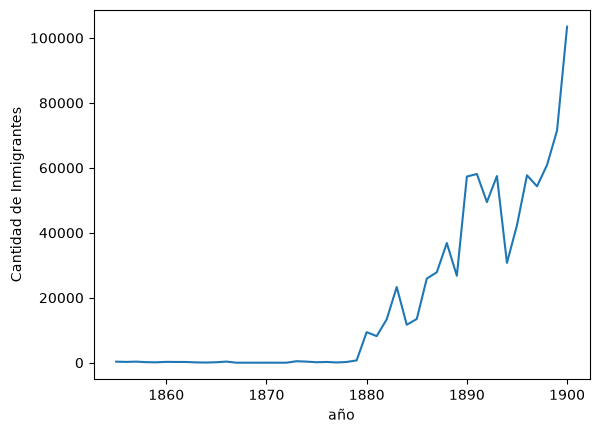

In [249]:
datos["año"].value_counts().sort_index().plot(kind="line", xlabel="año", ylabel="Cantidad de Inmigrantes")  

# Aca podemos ver que la cantidad de inmigrantes italianos fue aumentando a lo largo de los años, teniendo un aumento significativo a partir de 1897.

In [250]:
datos["edad"].corr(datos["año"]).round(0) # Tiene alguna relacion la edad promedio de los inmigrantes italianos con el año de llegada?

np.float64(-0.0)

## 9. Conclusión

A partir del análisis del registro de inmigración italiana (1855-1900), se desprenden los siguientes hallazgos clave:
1.  El flujo migratorio estuvo compuesto mayoritariamente por varones jóvenes (representando un 74.3% del total), con una edad promedio y mediana de entre 26 y 27 años, orientados principalmente a actividades de trabajo manual y agrícola (labradores, agricultores y jornaleros).
2.  Casi la totalidad de los pasajeros (96.2%) viajaba en tercera clase (*Steerage*), evidenciando que se trataba de una migración de carácter económico y popular en búsqueda de nuevas oportunidades.
3.  Se detectaron y normalizaron importantes desafíos en la fuente original, tales como altos porcentajes de valores no especificados ("DESCONOCIDO" o "U") en alfabetización y última residencia. Su correcto tratamiento permitió aislar los datos sin sesgar las métricas principales.
4. El flujo migratorio presentó variaciones interanuales marcadas a lo largo de las cuatro décadas analizadas, reflejando el impacto de los contextos socioeconómicos tanto en Europa como en los destinos de llegada.

In [251]:
datos.to_csv("datos/datos_limpios.csv", index=False) # Guardamos el df limpio en un csv para poder usarlo en streamlit y hacer un dashboard.